In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt
from datasets import load_dataset, Image

In [117]:
# Huggingface is faster
dataset = load_dataset("uoft-cs/cifar10")

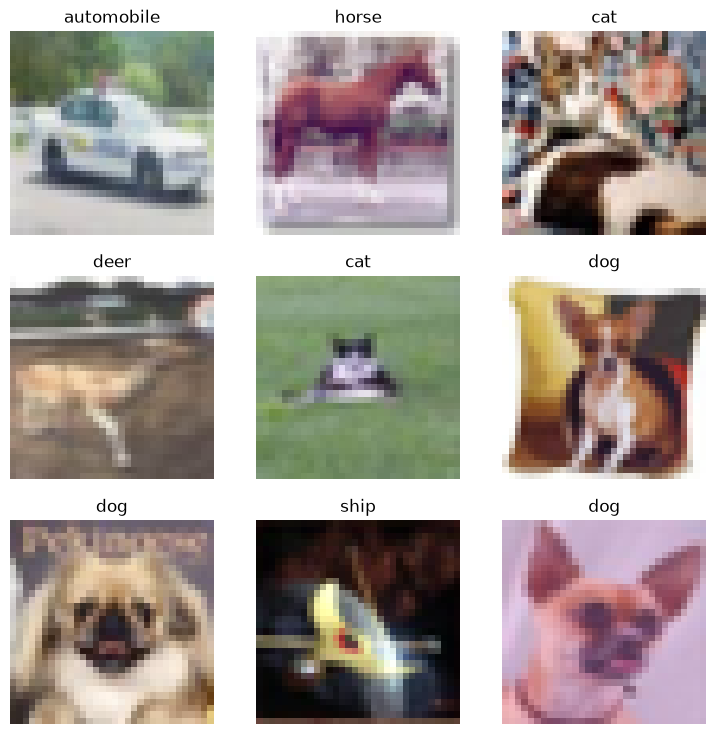

In [119]:
transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

# This function must return the transformed dataset
def apply_transforms(examples):
    examples["img"] = [transforms(img) for img in examples["img"]]
    return examples

train_val = dataset["train"].train_test_split(test_size = 0.2, seed=111)

train = train_val["train"]
val = train_val["test"]
test = dataset["test"]

train = train.with_transform(apply_transforms)
val = val.with_transform(apply_transforms)
test = test.with_transform(apply_transforms)

# HuggingFace datasets preserve the class-index order. This is valid.
labels_map = dict(enumerate(train.features["label"].names))
classes = len(labels_map)

figure = plt.figure(figsize=(9, 9))
cols, rows = 3, 3

for i in range(1, cols * rows + 1):
    idx = i - 1
    img = train[i]["img"]
    label = train[i]["label"]
    figure.add_subplot(rows, cols, i),
    plt.title(labels_map[label]),
    plt.axis("off"),
    plt.imshow(img.permute(1, 2, 0)),

plt.show()

In [101]:
batch_size = 64
    
train_dataloader = DataLoader(train.with_format("torch"), batch_size=batch_size)
val_dataloader = DataLoader(val.with_format("torch"), batch_size=batch_size)
test_dataloader = DataLoader(test.with_format("torch"), batch_size=batch_size)

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, *args):
        self.layers = nn.Sequential(*args)

    def forward(x):
        o = self.layers(x)
        return o + x

# 34-layer resnet as seen in the paper
class ResNet34(nn.Module):
    def __init__(self):
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 64,q
        )

In [99]:
for batch in train_dataloader:
    X = batch["img"]
    y = batch["label"]

    print(X.shape, y.shape)
    break

torch.Size([4, 3, 32, 32]) torch.Size([4])


In [ ]:
criterion = nn.CrossEntropyLoss()
model = LeNet5().to(device)
optimizer = optim.SGD([p for p in model.parameters()])

num_epochs = 10

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    # Loss for this epoch
    train_loss /= len(train_data)

    # Validation
    model.eval()
    valid_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            valid_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    valid_loss /= total
    accuracy = correct / total

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Valid Loss: {valid_loss:.4f} | "
        f"Valid Accuracy: {accuracy:.2%}"
    )